In [237]:
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV

from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay, confusion_matrix

In [171]:
TARGET_COL = 'target'

In [172]:
iris = load_iris(as_frame=True)
df = iris.frame

In [173]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [174]:
print(f"The shape of df : {df.shape}")
print('-'*25)
print(f"The data type of each column : {df.dtypes}")
print('-'*25)
print(f"The number of missing values per column : {df.isnull().sum()}")
print('-'*25)
print(f"Duplicate rows : {df.duplicated().sum()}")
print('-'*25)
print(f"How many rows each target class : {df[TARGET_COL].value_counts()}")

The shape of df : (150, 5)
-------------------------
The data type of each column : sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
dtype: object
-------------------------
The number of missing values per column : sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64
-------------------------
Duplicate rows : 1
-------------------------
How many rows each target class : target
0    50
1    50
2    50
Name: count, dtype: int64


In [175]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [176]:
dup = df[df.duplicated(keep=False)]
dup

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
101,5.8,2.7,5.1,1.9,2
142,5.8,2.7,5.1,1.9,2


In [177]:
dup.index.tolist()

[101, 142]

In [178]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [179]:
df[TARGET_COL].unique()

array([0, 1, 2])

## Remove duplicates BEFORE splitting

In [180]:
df = df.drop_duplicates()

In [181]:
df.duplicated().sum()

np.int64(0)

In [182]:
df.shape

(149, 5)

In [183]:
X = df.drop(columns=TARGET_COL)
y = df[TARGET_COL]

In [184]:
X.duplicated().sum()

np.int64(0)

In [185]:
print(df[TARGET_COL].value_counts())

target
0    50
1    50
2    49
Name: count, dtype: int64


In [186]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [187]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((119, 4), (30, 4), (119,), (30,))

In [188]:
y_train.value_counts(), y_test.value_counts()

(target
 0    40
 1    40
 2    39
 Name: count, dtype: int64,
 target
 1    10
 2    10
 0    10
 Name: count, dtype: int64)

In [189]:
print(y_train.value_counts(normalize=True).round(2))
print('-'*25)
print(y_test.value_counts(normalize=True).round(2))

target
0    0.34
1    0.34
2    0.33
Name: proportion, dtype: float64
-------------------------
target
1    0.33
2    0.33
0    0.33
Name: proportion, dtype: float64


### EDA on the training set

In [190]:
train_df = X_train.copy()
train_df[TARGET_COL] = y_train
train_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
6,4.6,3.4,1.4,0.3,0
128,6.4,2.8,5.6,2.1,2
95,5.7,3.0,4.2,1.2,1
44,5.1,3.8,1.9,0.4,0
30,4.8,3.1,1.6,0.2,0


In [191]:
train_df["species"] = train_df[TARGET_COL].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})
train_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
6,4.6,3.4,1.4,0.3,0,setosa
128,6.4,2.8,5.6,2.1,2,virginica
95,5.7,3.0,4.2,1.2,1,versicolor
44,5.1,3.8,1.9,0.4,0,setosa
30,4.8,3.1,1.6,0.2,0,setosa


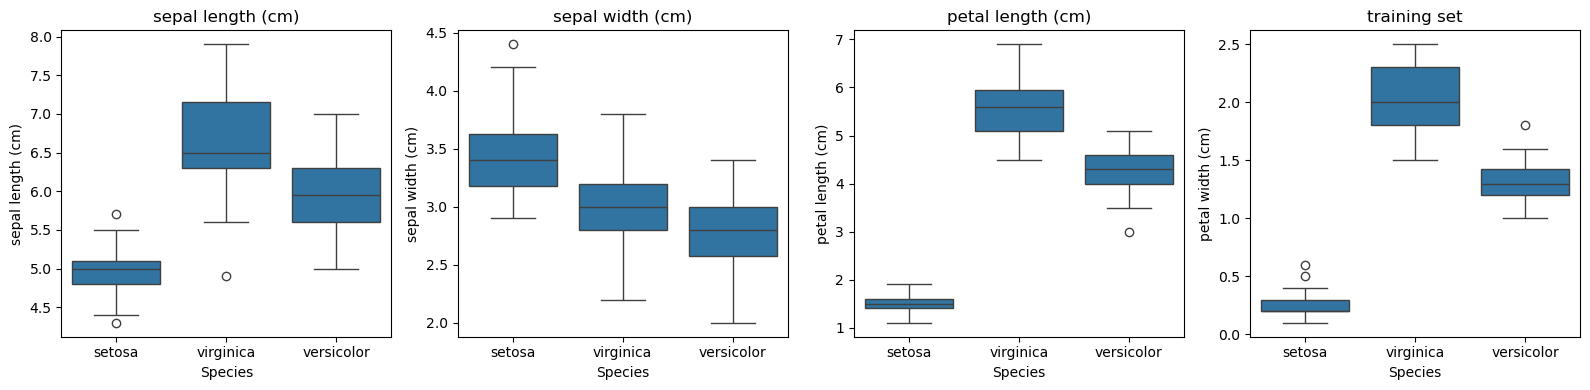

In [192]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, X_train.columns):
    sns.boxplot(data=train_df, x='species', y=col, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Species")
    ax.set_ylabel(col)
plt.title("training set")
plt.tight_layout()
plt.show()

In [193]:
print(train_df.shape)

(119, 6)


## Correlation heatmap

In [194]:
corr = X_train.corr()
corr.round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.00,-0.15,0.88,0.82
sepal width (cm),-0.15,1.00,-0.43,-0.36
petal length (cm),0.88,-0.43,1.00,0.96
petal width (cm),0.82,-0.36,0.96,1.00


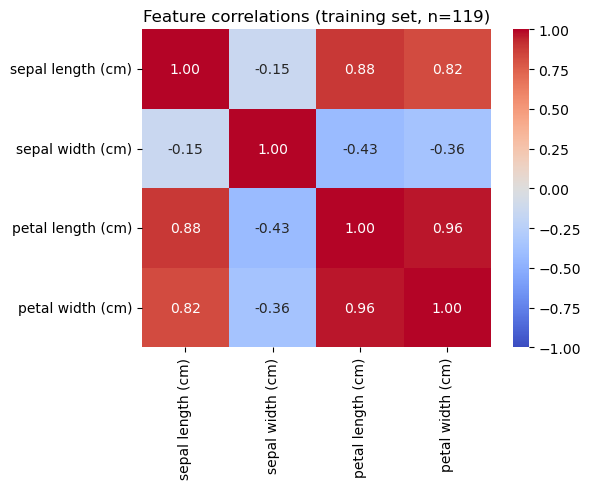

In [195]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Feature correlations (training set, n=119)")
plt.tight_layout()
plt.show()

## Preprocessing in a Pipeline

In [196]:
nums_cols = X_train.columns.to_list()
nums_cols

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [197]:
preprocessor = ColumnTransformer([
    ('scale', StandardScaler(), nums_cols)
])

In [198]:
preprocessor

ColumnTransformer(transformers=[('scale', StandardScaler(),
                                 ['sepal length (cm)', 'sepal width (cm)',
                                  'petal length (cm)', 'petal width (cm)'])])

In [199]:
X_train_scaled = preprocessor.fit_transform(X_train)
pd.DataFrame(X_train_scaled).head()

,0,1,2,3
0,-1.501587,0.769031,-1.339093,-1.179737
1,0.639824,-0.586742,1.041834,1.186365
2,-0.192947,-0.134818,0.248192,0.003314
3,-0.906751,1.672881,-1.055649,-1.048287
4,-1.263653,0.091144,-1.225715,-1.311187


In [200]:
X_test_scaled = preprocessor.transform(X_test)
pd.DataFrame(X_test_scaled).head()

,0,1,2,3
0,-0.311914,-1.264629,0.078126,-0.128136
1,-0.311914,-0.134818,0.418258,0.397664
2,1.234661,0.091144,0.758390,1.449265
3,-1.025718,0.769031,-1.282404,-1.311187
4,0.758791,-0.134818,0.815079,1.054914


In [201]:
X_train_scaled.shape, X_test_scaled.shape

((119, 4), (30, 4))

In [202]:
print("X_train_scaled")
print("Mean :",X_train_scaled.mean(axis=0).round(2))
print("STD :",X_train_scaled.std(axis=0).round(2))

X_train_scaled
Mean : [-0.  0.  0.  0.]
STD : [1. 1. 1. 1.]


In [203]:
print("X_test_scaled")
print("Mean :",X_test_scaled.mean(axis=0).round(2))
print("STD :",X_test_scaled.std(axis=0).round(2))

X_test_scaled
Mean : [-0.11  0.   -0.04 -0.02]
STD : [0.92 0.91 0.99 1.  ]


## Baseline first, then stronger models

In [204]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [205]:
models = {
    "baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
    "logistic regression": LogisticRegression(max_iter=1000),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5)
}

In [206]:
scoring = ["accuracy", "f1_macro"]
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    print(name)
    for s in scoring:
        print(f"  {s}: mean={scores['test_'+s].mean():.3f}, std={scores['test_'+s].std():.3f}")
    print()

baseline (most frequent)
  accuracy: mean=0.336, std=0.006
  f1_macro: mean=0.168, std=0.002

logistic regression
  accuracy: mean=0.966, std=0.051
  f1_macro: mean=0.963, std=0.056

KNN (k=5)
  accuracy: mean=0.957, std=0.048
  f1_macro: mean=0.956, std=0.050



In [207]:
print(len(X_train))

119


### Tune with cross-validation

In [208]:
knn_grid = {"model__n_neighbors": [1, 3, 5, 7, 9, 11, 15]}
lr_grid  = {"model__C": [0.01, 0.1, 1, 10, 100]}
knn_grid, lr_grid

({'model__n_neighbors': [1, 3, 5, 7, 9, 11, 15]},
 {'model__C': [0.01, 0.1, 1, 10, 100]})

In [210]:
lr_pipe = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(max_iter=1000))
])
knn_pipe = Pipeline([
    ('prep', preprocessor),
    ('model', KNeighborsClassifier(n_neighbors=5))
])

In [211]:
lr_search = GridSearchCV(lr_pipe, lr_grid, cv=cv, scoring='f1_macro')
lr_search.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('prep',
                                        ColumnTransformer(transformers=[('scale',
                                                                         StandardScaler(),
                                                                         ['sepal '
                                                                          'length '
                                                                          '(cm)',
                                                                          'sepal '
                                                                          'width '
                                                                          '(cm)',
                                                                          'petal '
                                                                          'length '
                                                                          '(cm)',
                                                                          'petal '
                                                                          'width '
                                                                          '(cm)'])])),
                                       ('model',
                                        LogisticRegression(max_iter=1000))]),
             param_grid={'model__C': [0.01, 0.1, 1, 10, 100]},
             scoring='f1_macro')

In [212]:
knn_search = GridSearchCV(knn_pipe, knn_grid, cv=cv, scoring='f1_macro')
knn_search.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('prep',
                                        ColumnTransformer(transformers=[('scale',
                                                                         StandardScaler(),
                                                                         ['sepal '
                                                                          'length '
                                                                          '(cm)',
                                                                          'sepal '
                                                                          'width '
                                                                          '(cm)',
                                                                          'petal '
                                                                          'length '
                                                                          '(cm)',
                                                                          'petal '
                                                                          'width '
                                                                          '(cm)'])])),
                                       ('model', KNeighborsClassifier())]),
             param_grid={'model__n_neighbors': [1, 3, 5, 7, 9, 11, 15]},
             scoring='f1_macro')

In [213]:
print('Logistic Regression')
print(lr_search.best_params_)
print(lr_search.best_score_)

Logistic Regression
{'model__C': 1}
0.9629258529568128


In [214]:
print('kNN')
print(knn_search.best_params_)
print(knn_search.best_score_)

kNN
{'model__n_neighbors': 3}
0.956118652589241


In [215]:
pd.DataFrame(lr_search.cv_results_)[["params", "mean_test_score", "std_test_score"]]

,params,mean_test_score,std_test_score
0,{'model__C': 0.01},0.878170,0.072142
1,{'model__C': 0.1},0.920999,0.061561
2,{'model__C': 1},0.962926,0.055644
3,{'model__C': 10},0.945995,0.054658
4,{'model__C': 100},0.945995,0.054658


In [224]:
final_model = lr_search.best_estimator_ # we chose this model cause has best score 0.963

In [225]:
train_pred = final_model.predict(X_train)
test_pred = final_model.predict(X_test)

In [226]:
accuracy_score(y_test, test_pred), f1_score(y_test, test_pred, average="macro")

(0.9333333333333333, 0.9333333333333332)

In [229]:
print(classification_report(y_test, test_pred, target_names=iris.target_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [228]:
len(X_test)

30

In [239]:
print(accuracy_score(y_train, train_pred))
print(f1_score(y_train, train_pred, average="macro"))

0.957983193277311
0.9577788466677356


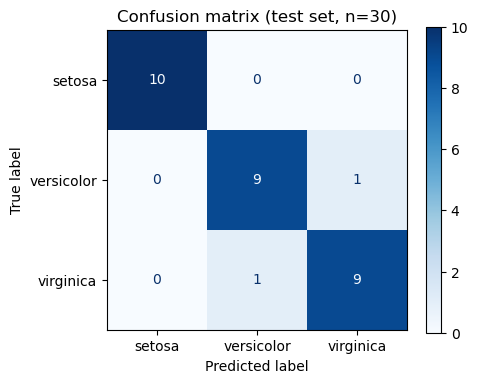

In [235]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=iris.target_names, ax=ax, cmap="Blues")
ax.set_title("Confusion matrix (test set, n=30)")
plt.tight_layout()
plt.show()

In [238]:
print(confusion_matrix(y_test, test_pred))

[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


In [241]:
lr = final_model.named_steps["model"]
feature_names = X_train.columns.tolist()

In [242]:
lr.coef_.shape

(3, 4)

In [244]:
coef_df = pd.DataFrame(lr.coef_, index=iris.target_names, columns=feature_names)
coef_df.round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
setosa,-1.05,1.17,-1.70,-1.63
versicolor,0.56,-0.47,-0.29,-0.81
virginica,0.48,-0.70,1.99,2.45


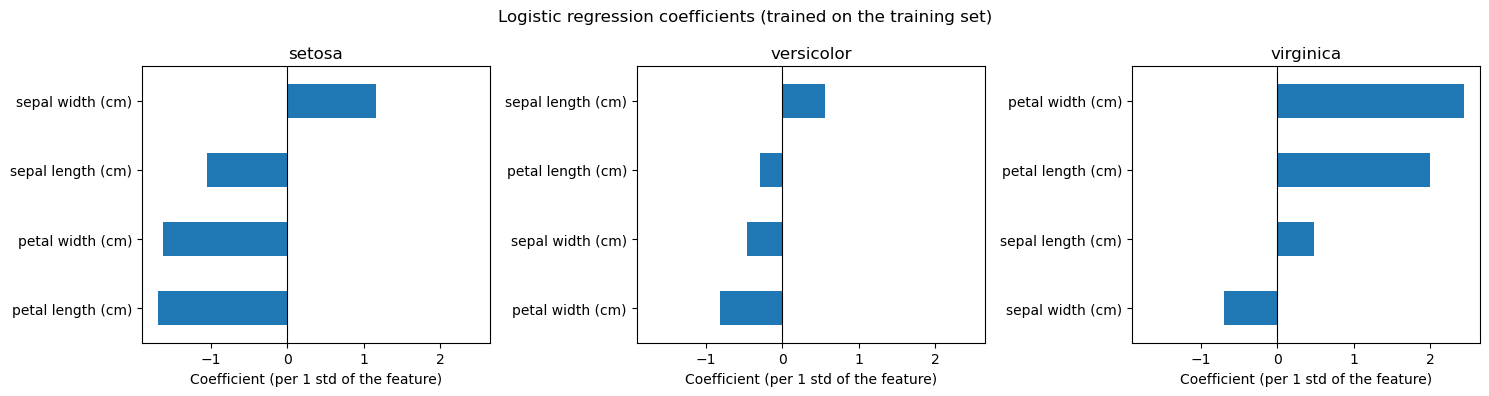

In [249]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, species in zip(axes, coef_df.index):
    coef_df.loc[species].sort_values().plot.barh(ax=ax)
    ax.set_title(species)
    ax.set_xlabel("Coefficient (per 1 std of the feature)")
    ax.axvline(0, color="black", linewidth=0.8)
fig.suptitle("Logistic regression coefficients (trained on the training set)")
plt.tight_layout()
plt.show()